In [2]:
import argparse
import sys
import contextlib
import logging
import os
import time
import traceback
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
from flwr.simulation import run_simulation
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.metrics import auc as sk_auc
 
import config
import fl_basic6 as fl            # <- modul strategy/client versi lengkap
from dataset import DROP_COLS, TARGET
 
# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)
 
SEEDS = [42, 0, 123, 1337, 3407]
 
# Metrik dari fl_core: acc, prec, rec, f1, auc, prauc (prauc = Average Precision)
METRIK = list(fl.METRIK)
TEST_COLS = METRIK                                   # test pooled
VAL_COLS = [f'val_{k}' for k in METRIK]              # val pooled (model akhir)
EXTRA_COLS = ['f1_macro_klien', 'f1_std_klien', 'val_f1_macro_klien',
              'val_f1_akhir', 'val_f1_terbaik', 'prauc_trapz',
              'total_MB', 'waktu_s']
ALL_COLS = TEST_COLS + VAL_COLS + EXTRA_COLS
PAIRED_METRICS = ('f1', 'auc', 'prauc')
 
# ---- logging ----
VERBOSE = False                          # True = semua print tampil di konsol
LOG_DIR = ORIG_OUT_DIR.parent
LOG_DIR.mkdir(parents=True, exist_ok=True)
LOG_FLWR = LOG_DIR / 'flwr.log'
LOG_PRINTS = LOG_DIR / 'prints.log'
 
 
def setup_flwr_logging():
    """Console Flower hanya WARNING+; detail penuh ke file. Aman dipanggil berulang."""
    lg = logging.getLogger("flwr")
    for h in lg.handlers:
        if not isinstance(h, logging.FileHandler):
            h.setLevel(logging.WARNING)
    if not any(isinstance(h, logging.FileHandler) for h in lg.handlers):
        fh = logging.FileHandler(LOG_FLWR, encoding="utf-8")
        fh.setLevel(logging.INFO)
        fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
        lg.addHandler(fh)
    lg.setLevel(logging.INFO)
 
 
@contextlib.contextmanager
def quiet(logfile=None):
    """Alihkan print() ke file. Dinonaktifkan bila VERBOSE."""
    if VERBOSE:
        yield
        return
    with open(logfile or LOG_PRINTS, "a", encoding="utf-8") as f, \
            contextlib.redirect_stdout(f):
        yield
 
 
setup_flwr_logging()

In [3]:

# %%
# ============================================================
# 1. DATASET, MODUL & RINGKASAN DATA
# ============================================================
def setup_dataset():
    """Arahkan config ke folder dataset dan buang cache data lama."""
    if not CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {CLIENT_DIR}")
    config.CLIENT_DIR = CLIENT_DIR
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")
 
 
def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    print(f"Metrik  : {METRIK}")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")
    else:
        print("Agregasi pairwise: TIDAK tersedia (aggregation4 gagal diimpor)")
 
 
def available_algos(algos):
    known = set(getattr(fl, 'ALGOS', algos))
    ok, skip = [], []
    for a in algos:
        if a not in known:
            skip.append(a)
        elif a == 'fedpairwise' and getattr(fl, 'FedCosinePairwise', None) is None:
            skip.append(a)
        else:
            ok.append(a)
    if skip:
        print(f"[lewati] tidak tersedia di {fl.__name__}: {skip}")
    return ok
 
 
def data_summary():
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
    print("=" * 50)
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")
 
    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}
 
    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total
 
    print("\nRingkasan per client:")
    print(ringkas.to_string())
 
    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients
 
 
# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    for nama in ('final_params.npz', 'ronde_log.csv', 'ronde_val_per_client.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    setup_flwr_logging()
    with quiet():
        run_simulation(
            server_app=fl.make_server_app(algo),
            client_app=fl.make_client_app(),
            num_supernodes=n_clients,
            backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
        )
 
 
def load_global_model():
    """Bobot global terakhir -> model (memakai fl.load_final_model)."""
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    return fl.load_final_model(path)
 
 
# %%
# ============================================================
# 2b. METRIK DIAGNOSTIK: kurva ROC & PR
# ============================================================
def _to_prob(out):
    """Ubah output model (logit / prob / 2 kelas) menjadi P(kelas=1), shape (n,)."""
    out = np.asarray(out, dtype=np.float64)
    if out.ndim == 2 and out.shape[1] == 2:
        if out.min() < 0 or out.max() > 1 or not np.allclose(out.sum(1), 1, atol=1e-3):
            e = np.exp(out - out.max(1, keepdims=True))
            out = e / e.sum(1, keepdims=True)
        return out[:, 1]
    out = out.reshape(-1)
    if out.min() < 0.0 or out.max() > 1.0:
        out = 1.0 / (1.0 + np.exp(-out))
    return out
 
 
def predict_proba_clients(model, split='test'):
    clients, _, _ = fl.load_data()
    model.eval()
    ys, ps = {}, {}
    with torch.no_grad():
        for st, c in clients.items():
            xk, yk = f'X_{split}_t', f'y_{split}_t'
            if xk not in c:
                raise KeyError(f"Kunci '{xk}' tidak ada di data client. "
                               f"Kunci tersedia: {list(c.keys())}")
            out = model(c[xk].float().to(config.DEVICE)).detach().cpu().numpy()
            ps[st] = _to_prob(out)
            ys[st] = c[yk].detach().cpu().numpy().reshape(-1).astype(int)
    return ys, ps
 
 
def diagnostic_metrics(model, split='test'):
    """AUC-ROC & AP gabungan + AUC/AP per state + titik kurva ROC & PR gabungan."""
    ys, ps = predict_proba_clients(model, split)
    y_all = np.concatenate(list(ys.values()))
    p_all = np.concatenate(list(ps.values()))
 
    def _safe(fn, y, p):
        return float(fn(y, p)) if 0 < y.sum() < len(y) else float('nan')
 
    per_state = pd.DataFrame({
        st: {'auc': _safe(roc_auc_score, ys[st], ps[st]),
             'ap': _safe(average_precision_score, ys[st], ps[st]),
             'prevalensi': float(ys[st].mean())}
        for st in ys}).T
    per_state.index.name = 'state'
 
    fpr, tpr, _ = roc_curve(y_all, p_all)
    prec, rec, _ = precision_recall_curve(y_all, p_all)
    return {
        'auc': _safe(roc_auc_score, y_all, p_all),
        'ap': _safe(average_precision_score, y_all, p_all),
        'prevalensi': float(y_all.mean()),
        'per_state': per_state,
        'roc': (fpr, tpr),
        'pr': (rec, prec),
    }
 
 
def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)
 
            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))
 
            model = load_global_model()
            # evaluasi lengkap VAL + TEST semua client (acc, prec, rec, f1, auc, prauc)
            fl.full_report(model, splits=('val', 'test'), save=True, verbose=True)
 
            diag = diagnostic_metrics(model, 'test')
            print(f"\nAUC-ROC gabungan (test) : {diag['auc']:.4f}")
            print(f"PR-AUC/AP gabungan (test): {diag['ap']:.4f}  "
                  f"(garis dasar acak = prevalensi {diag['prevalensi']:.4f})")
    finally:
        config.SEED = ORIG_SEED

Modul FL: fl_basic6 (fl_basic6.py)
Metrik  : ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
Agregasi pairwise dari modul: aggregation4
Dataset : C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients (45 item)
Jumlah client (state) : 44
Daftar state          : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 44 dari 44
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwa

[selesai] fedavg s42: VAL F1 0.4737 AP 0.4326 | TEST F1 0.4656 AUC 0.7357 PR-AUC 0.4296 | 34.99 MB | 68.4 s

########## fedprox | seed 42 ##########


[selesai] fedprox s42: VAL F1 0.4773 AP 0.4349 | TEST F1 0.4668 AUC 0.7373 PR-AUC 0.4322 | 34.99 MB | 88.1 s

########## fedavgm | seed 42 ##########


[selesai] fedavgm s42: VAL F1 0.3844 AP 0.3371 | TEST F1 0.3746 AUC 0.6473 PR-AUC 0.3293 | 34.99 MB | 69.1 s

########## fedadam | seed 42 ##########


[selesai] fedadam s42: VAL F1 0.4581 AP 0.3874 | TEST F1 0.4440 AUC 0.7142 PR-AUC 0.3858 | 34.99 MB | 69.2 s

########## fedpairwise | seed 42 ##########


...

[selesai] fedavg s3407: VAL F1 0.4781 AP 0.4399 | TEST F1 0.4661 AUC 0.7355 PR-AUC 0.4257 | 34.99 MB | 71.5 s

########## fedprox | seed 3407 ##########


[selesai] fedprox s3407: VAL F1 0.4782 AP 0.4416 | TEST F1 0.4678 AUC 0.7369 PR-AUC 0.4275 | 34.99 MB | 91.5 s

########## fedavgm | seed 3407 ##########


[selesai] fedavgm s3407: VAL F1 0.3010 AP 0.2786 | TEST F1 0.2963 AUC 0.5921 PR-AUC 0.2624 | 34.99 MB | 72.5 s

########## fedadam | seed 3407 ##########


[selesai] fedadam s3407: VAL F1 0.4559 AP 0.3923 | TEST F1 0.4423 AUC 0.7129 PR-AUC 0.3840 | 34.99 MB | 69.5 s

########## fedpairwise | seed 3407 ##########


[selesai] fedpairwise s3407: VAL F1 0.4815 AP 0.4457 | TEST F1 0.4676 AUC 0.7394 PR-AUC 0.4340 | 34.99 MB | 73.9 s

PERBANDINGAN AGREGASI - TEST (pooled; rata-rata ± std antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc            prauc
algoritma                                                                                                                
fedpairwise       5  0.7006 ± 0.0043  0.3728 ± 0.0038  0.6321 ± 0.0060  0.4690 ± 0.0017  0.7399 ± 0.0006  0.4371 ± 0.0019
fedprox           5  0.6965 ± 0.0039  0.3691 ± 0.0028  0.6357 ± 0.0087  0.4670 ± 0.0006  0.7380 ± 0.0015  0.4327 ± 0.0033
fedavg            5  0.6981 ± 0.0038  0.3698 ± 0.0029  0.6292 ± 0.0074  0.4658 ± 0.0010  0.7370 ± 0.0014  0.4309 ± 0.0035
fedadam           5  0.6571 ± 0.0099  0.3376 ± 0.0065  0.6634 ± 0.0157  0.4473 ± 0.0045  0.7177 ± 0.0046  0.3940 ± 0.0110
fedavgm           5  0.7020 ± 0.0227  0.3192 ± 0.0356  0.3711 ± 0.0592  0.341

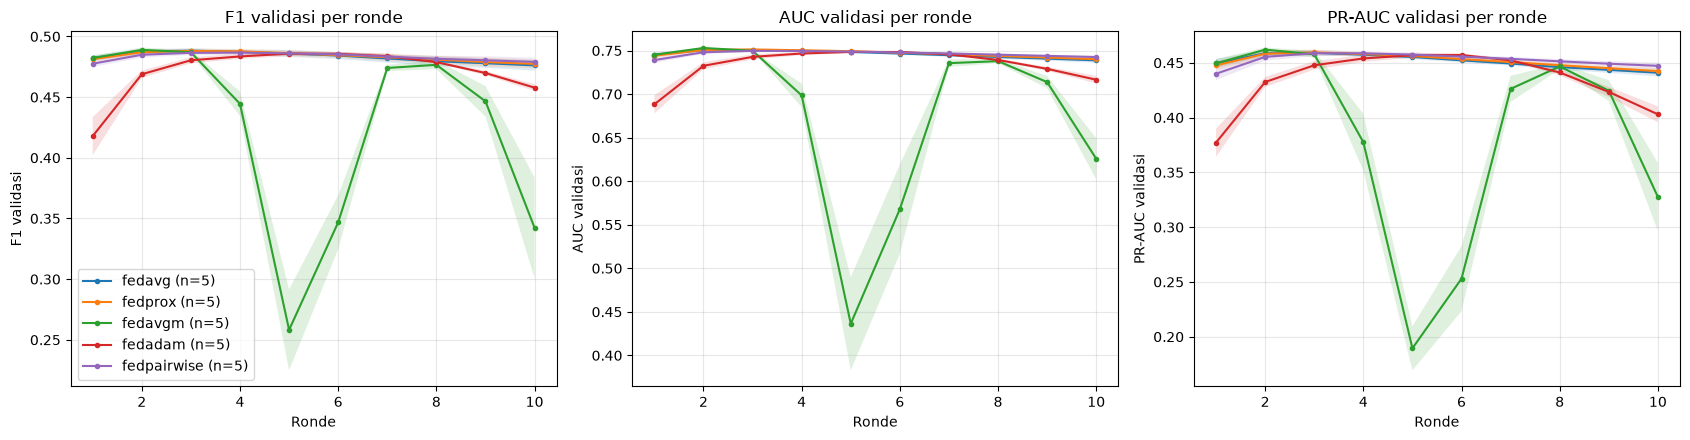

Grafik disimpan: C:\Users\s2\Documents\FIXRKI\FIXbanget\baselinefed\withoutEarlystoping\kurva_roc_pr_test.png


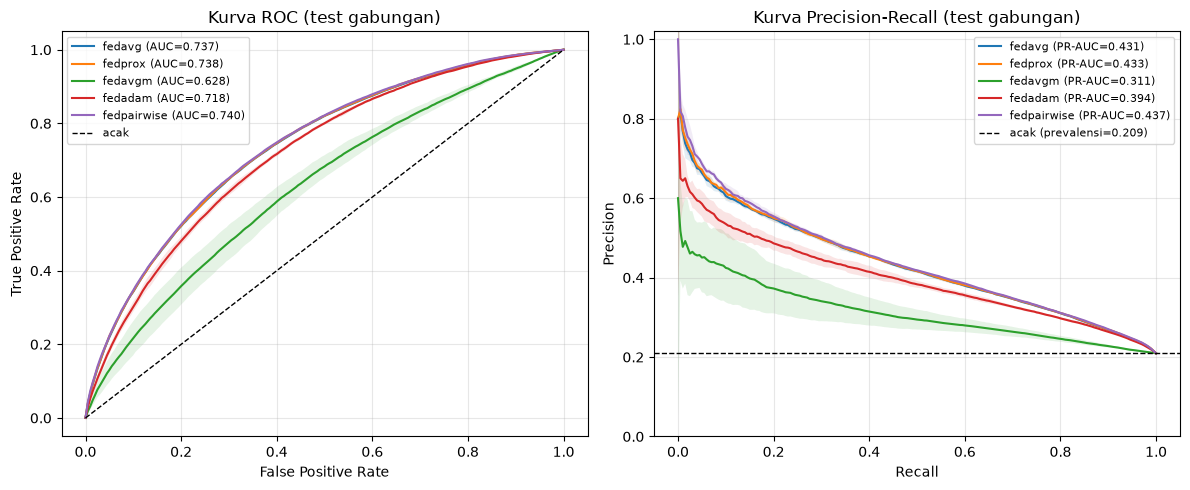

In [4]:

# %%
# ============================================================
# 3. KOMPARASI
# ============================================================
def collect_result(secs):
    model = load_global_model()
    res = fl.full_report(model, splits=('val', 'test'), save=True, verbose=False)
    te, va = res['test'], res['val']
    ronde = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _ = fl.bandwidth_report(verbose=False)
    diag = diagnostic_metrics(model, 'test')
 
    # --- log validasi per ronde (aman bila kosong / semua NaN) ---
    ronde = ronde.reset_index(drop=True)
    f1 = ronde['f1'].astype(float)
    val_akhir = float(f1.iloc[-1]) if len(f1) else float('nan')
    if f1.notna().any():
        best = f1.idxmax()
        val_best = float(f1[best])
        best_round = int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1
 
    # --- PR-AUC trapesium (selain AP) ---
    rec, prec = diag['pr']
    pr_trapz = float(sk_auc(rec, prec)) if len(rec) > 1 else float('nan')
 
    row = {}
    for k in METRIK:
        row[k] = float(te['pooled'][k])                 # test pooled
        row[f'val_{k}'] = float(va['pooled'][k])        # val pooled (model akhir)
    row['auc'] = diag['auc']                            # konsisten dgn diagnostic
    row['prauc'] = diag['ap']
    row.update({
        'prauc_trapz':        pr_trapz,
        'prevalensi':         diag['prevalensi'],
        'f1_macro_klien':     float(te['per_client']['f1'].mean()),
        'f1_std_klien':       float(te['per_client']['f1'].std()),
        'val_f1_macro_klien': float(va['per_client']['f1'].mean()),
        'val_f1_akhir':       val_akhir,        # F1 val berbobot ronde terakhir
        'val_f1_terbaik':     val_best,
        'ronde_terbaik':      best_round,
        'total_MB':           float(bw['total_MB']),
        'waktu_s':            round(secs, 1),
    })
    per_client = {'test': te['per_client'], 'val': va['per_client']}
    return row, per_client, ronde, diag
 
 
def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"
 
 
def summarize_seeds(per_seed):
    """Mean & std antar seed untuk semua kolom -> DataFrame numerik."""
    cols = [c for c in ALL_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')
 
    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    return num.sort_values('f1_mean', ascending=False)
 
 
def format_table(num, cols):
    """Tabel teks 'mean ± std' untuk sebagian kolom."""
    cols = [c for c in cols if f'{c}_mean' in num.columns]
    t = pd.DataFrame(index=num.index)
    t['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        t[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                     int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return t
 
 
def _pvalue(d):
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)
 
 
def paired_vs_baseline(per_seed, baseline, metrics=PAIRED_METRICS):
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None
 
 
def _get_plt():
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        return plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return None
 
 
def _finish(plt, fig, out_path):
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)
 
 
def plot_curves(kurva, out_path):
    """F1, AUC & PR-AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)
 
    panels = [('f1', 'F1 validasi'), ('auc', 'AUC validasi'),
              ('prauc', 'PR-AUC validasi')]
    fig, axes = plt.subplots(1, len(panels), figsize=(17, 4.5))
    for ax, (col, judul) in zip(axes, panels):
        for algo, rs in per_algo.items():
            rs = [r for r in rs if col in r.columns]
            if not rs:
                continue
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values,
                                alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde')
        ax.grid(alpha=0.3)
    axes[0].legend()
    _finish(plt, fig, out_path)
 
 
def plot_roc_pr(diags, out_path):
    """Kurva ROC & PR test gabungan: rata-rata antar seed, pita = ± std."""
    plt = _get_plt()
    if plt is None:
        return
    per_algo = {}
    for (algo, _), d in diags.items():
        per_algo.setdefault(algo, []).append(d)
 
    grid = np.linspace(0, 1, 201)
    fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 5))
 
    for algo, ds in per_algo.items():
        tprs = np.array([np.interp(grid, *d['roc']) for d in ds])
        precs = np.array([np.interp(grid, d['pr'][0][::-1], d['pr'][1][::-1])
                          for d in ds])
        auc_m = np.nanmean([d['auc'] for d in ds])
        ap_m = np.nanmean([d['ap'] for d in ds])
 
        mu = tprs.mean(0)
        ax_roc.plot(grid, mu, label=f'{algo} (AUC={auc_m:.3f})')
        mu_p = precs.mean(0)
        ax_pr.plot(grid, mu_p, label=f'{algo} (PR-AUC={ap_m:.3f})')
        if len(ds) > 1:
            sd = tprs.std(0, ddof=1)
            ax_roc.fill_between(grid, mu - sd, mu + sd, alpha=0.12)
            sd_p = precs.std(0, ddof=1)
            ax_pr.fill_between(grid, mu_p - sd_p, mu_p + sd_p, alpha=0.12)
 
    prev = np.mean([d['prevalensi'] for ds in per_algo.values() for d in ds])
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, label='acak')
    ax_pr.axhline(prev, color='k', ls='--', lw=1,
                  label=f'acak (prevalensi={prev:.3f})')
 
    ax_roc.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
               title='Kurva ROC (test gabungan)')
    ax_pr.set(xlabel='Recall', ylabel='Precision',
              title='Kurva Precision-Recall (test gabungan)', ylim=(0, 1.02))
    for ax in (ax_roc, ax_pr):
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=8)
    _finish(plt, fig, out_path)
 
 
def per_client_tables(per_client, algos):
    """{(split, metrik): DataFrame state x algoritma, rata-rata antar seed}."""
    tabel = {}
    for split in ('val', 'test'):
        for met in METRIK:
            t = pd.DataFrame({
                algo: pd.concat([per_client[k][split][met]
                                 for k in per_client if k[0] == algo],
                                axis=1).mean(axis=1)
                for algo in algos})
            t.loc['MAKRO'] = t.mean()
            tabel[(split, met)] = t
    return tabel
 
 
def run_compare(algos, seeds, n_clients, out_root):
    rows, per_client, kurva, diags = {}, {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")
    print(f"Log detail: {LOG_FLWR} | {LOG_PRINTS}")
 
    try:
        for seed in seeds:
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, pc, ronde, diag = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], per_client[key] = row, pc
                kurva[key], diags[key] = ronde, diag
                print(f"[selesai] {algo} s{seed}: "
                      f"VAL F1 {row['val_f1']:.4f} AP {row['val_prauc']:.4f} | "
                      f"TEST F1 {row['f1']:.4f} AUC {row['auc']:.4f} "
                      f"PR-AUC {row['prauc']:.4f} | "
                      f"{row['total_MB']:.2f} MB | {row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED
 
    if not rows:
        sys.exit("Tidak ada run yang berhasil.")
 
    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)
 
    num = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)
    tabel_klien = per_client_tables(per_client, list(num.index))
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI - TEST (pooled; rata-rata ± std antar seed; urut F1)")
    print("=" * 70)
    print(format_table(num, TEST_COLS).to_string())
 
    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI - VALIDASI (model akhir, pooled)")
    print("=" * 70)
    print(format_table(num, VAL_COLS).to_string())
 
    print("\n" + "=" * 70)
    print("LAINNYA (F1 antar client, val per ronde, bandwidth, waktu)")
    print("=" * 70)
    print(format_table(num, EXTRA_COLS).to_string())
 
    print("\nHasil per seed (VAL | TEST):")
    for split, pref in (('VAL', 'val_'), ('TEST', '')):
        cols = [f'{pref}f1', f'{pref}auc', f'{pref}prauc']
        print(f"\n[{split}] F1 | AUC | PR-AUC")
        print(per_seed[cols].round(4).unstack('seed').to_string())
 
    if berpasangan is not None:
        print(f"\nSelisih TEST terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; lihat kolom *_menang dan "
                  "konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/gagal.")
 
    for split in ('val', 'test'):
        for met in ('f1', 'prauc'):
            print(f"\n{met.upper()} {split.upper()} per state (rata-rata antar seed):")
            print(tabel_klien[(split, met)].round(4).to_string())
 
    print(f"\nTerbaik F1 test (rata-rata)     : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC test (rata-rata)    : {num['auc_mean'].idxmax()}")
    print(f"Terbaik PR-AUC test (rata-rata) : {num['prauc_mean'].idxmax()}")
    print(f"Terbaik F1 val (rata-rata)      : {num['val_f1_mean'].idxmax()}")
    print(f"Terbaik PR-AUC val (rata-rata)  : {num['val_prauc_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed        : {num['f1_std'].idxmin()} "
              f"(std F1 test terkecil)")
    print(f"Paling merata antar state       : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():
        print(f"Bandwidth terkecil              : {mb.idxmin()}")
    else:
        print("Bandwidth                       : sama untuk semua algoritma")
 
    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    for (split, met), t in tabel_klien.items():
        t.to_csv(out_root / f'perbandingan_{split}_{met}_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    plot_roc_pr(diags, out_root / 'kurva_roc_pr_test.png')
    return per_seed, num
 
 
# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    args, _ = ap.parse_known_args(argv)
 
    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
 
    show_modules()
    setup_dataset()
    n_clients = data_summary()
    if args.info:
        return
 
    out_root = ORIG_OUT_DIR.parent
 
    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)
 
 
if __name__ == '__main__':
    main()